## Decision Tree Classifier Assignment

## Step 1: Data Gathering

In [1]:
import pandas as pd
from sklearn.datasets import load_wine
df_x,y_series = load_wine(as_frame=True,return_X_y=True)
y=pd.DataFrame(y_series)

In [ ]:
# !st 10 records
df_x.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [3]:
y.head()

,target
0,0
1,0
2,0
3,0
4,0


In [4]:
# Shape
print(df_x.shape,y.shape)

(178, 13) (178, 1)


In [5]:
# Feature Names
df_x.columns

Index(['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium',
       'total_phenols', 'flavanoids', 'nonflavanoid_phenols',
       'proanthocyanins', 'color_intensity', 'hue',
       'od280/od315_of_diluted_wines', 'proline'],
      dtype='str')

In [6]:
y.columns

Index(['target'], dtype='str')

## Step:2 EDA

In [10]:
# Checking data types
df_x.dtypes

alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
dtype: object

In [11]:
y.dtypes

target    int64
dtype: object

In [ ]:
# missing values
df_x.isna().sum()

alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64

In [13]:
y.isna().sum()

target    0
dtype: int64

In [14]:
# Duplicated records
df_x.duplicated().sum()

np.int64(0)

In [15]:
# Statistical Summary
df_x.describe()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


In [16]:
y.describe()

,target
count,178.000000
mean,0.938202
std,0.775035
min,0.000000
25%,0.000000
50%,1.000000
75%,2.000000
max,2.000000


In [17]:
# Class Distribution 
y['target'].value_counts()

target
1    71
0    59
2    48
Name: count, dtype: int64

## Step 3 : Data Visualization

<Axes: xlabel='target'>

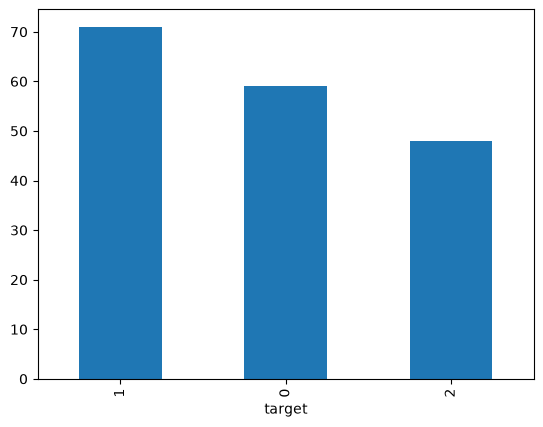

In [ ]:
# Class Distribution Plot
y['target'].value_counts().plot(kind='bar')

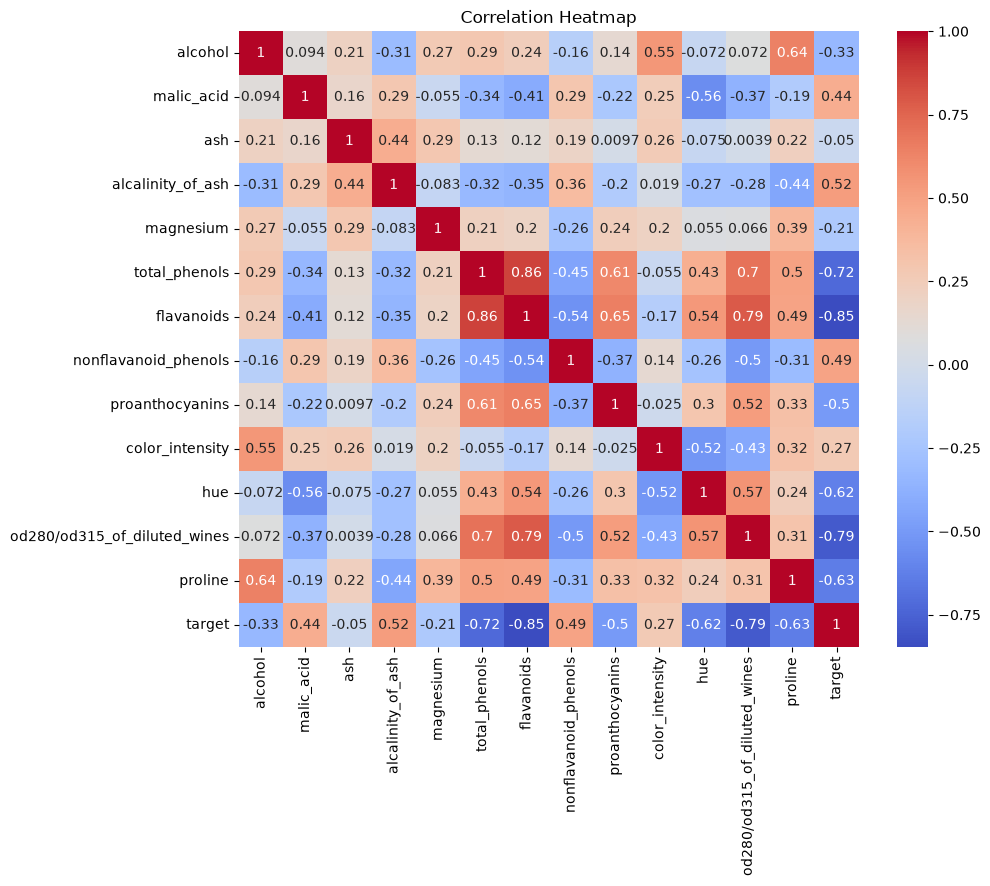

In [19]:
# Correlation Heatmap
import seaborn as sns
import matplotlib.pyplot as plt
data = df_x.copy()
data["target"]= y
plt.figure(figsize=(10,8))
sns.heatmap(data.corr(),annot= True, cmap= "coolwarm")
plt.title("Correlation Heatmap")
plt.show()


## Here we can see correlation between 
1. target and od280/od315_of_diluted_wines
2. target and flavanoids

In [21]:
# Histogram of selected features
import matplotlib.pyplot as plt
plt.hist(df_x['od280/od315_of_diluted_wines'],y['target'],bins= 20)
plt.xlabel("od280/od315_of_diluted_wines")
plt.ylabel("target")
plt.title("Distribution of od280/od315_of_diluted_wines")
plt.show()

TypeError: hist() got multiple values for argument 'bins'